# 📊 Phase 6: Exploratory Data Analysis

Numbers in tables are useful. But a well-made chart makes the business sit up and pay attention.

Every chart here answers a specific business question — and every result comes with a clear takeaway explaining what it means and what action it suggests.

---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style("whitegrid")

orders      = pd.read_csv('../../02_Data/03_Processed_Data/orders_featured.csv',
                           parse_dates=['order_purchase_timestamp'])
customers   = pd.read_csv('../../02_Data/02_Cleaned_Data/customers_clean.csv')
payments    = pd.read_csv('../../02_Data/02_Cleaned_Data/payments_clean.csv')
order_items = pd.read_csv('../../02_Data/02_Cleaned_Data/order_items_clean.csv')
products    = pd.read_csv('../../02_Data/02_Cleaned_Data/products_clean.csv')
reviews     = pd.read_csv('../../02_Data/02_Cleaned_Data/reviews_clean.csv')

os.makedirs('../../05_Analytics/03_Visualizations', exist_ok=True)
print("✅ Ready for EDA!")

✅ Ready for EDA!


## 📈 Chart 1: Monthly Revenue Trend
*Is the business growing — and when does it peak?*

The first question any stakeholder asks is whether the business is heading in the right direction. Monthly revenue over time gives the clearest answer.

---

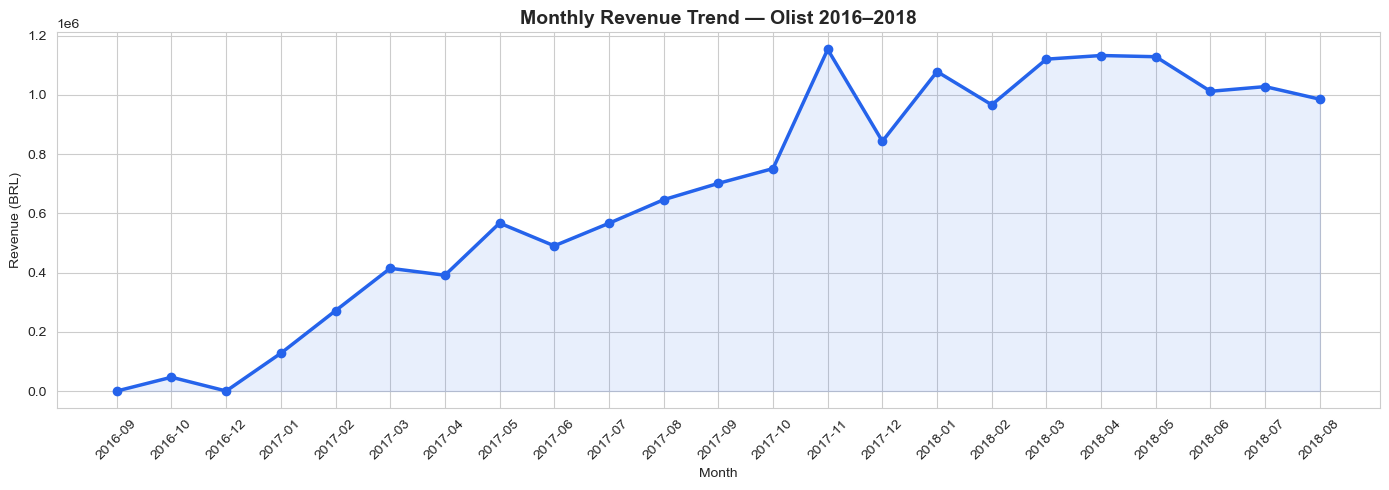

💡 Revenue peaked Nov 2017 — Black Friday. Steady growth through 2018.


In [2]:
order_rev = payments.groupby('order_id')['payment_value'].sum().reset_index()
orders_merged = orders.merge(order_rev, on='order_id', how='left')

monthly = orders_merged.groupby(
    orders_merged['order_purchase_timestamp'].dt.to_period('M')
)['payment_value'].sum().reset_index()
monthly.columns = ['month', 'revenue']
monthly['month'] = monthly['month'].astype(str)

plt.figure(figsize=(14, 5))
plt.plot(monthly['month'], monthly['revenue'],
         marker='o', color='#2563EB', linewidth=2.5)
plt.fill_between(range(len(monthly)), monthly['revenue'],
                 alpha=0.1, color='#2563EB')
plt.xticks(range(len(monthly)), monthly['month'], rotation=45)
plt.title('Monthly Revenue Trend — Olist 2016–2018',
          fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Revenue (BRL)')
plt.tight_layout()
plt.savefig('../../05_Analytics/03_Visualizations/01_monthly_revenue.png', dpi=150)
plt.show()
print("💡 Revenue peaked Nov 2017 — Black Friday. Steady growth through 2018.")

## 🗺️ Chart 2: Top 10 States by Revenue
*Where are Olist's strongest markets?*

Brazil has 26 states but they don't all contribute equally. This tells the business exactly where to focus marketing and logistics investment first.

---

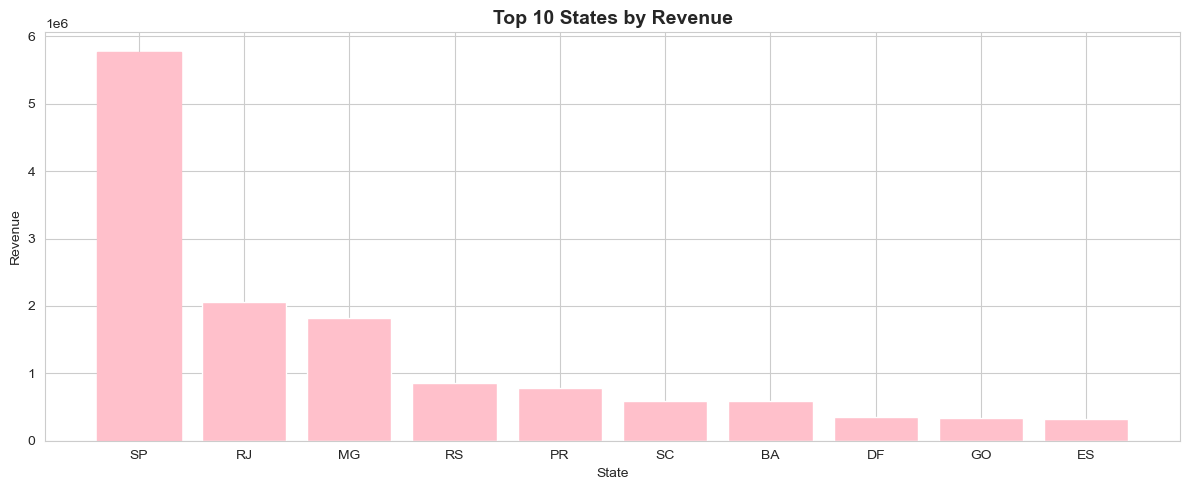

 São Paulo generates nearly 40% of all revenue — far ahead of every other state.


In [7]:
merged = orders.merge(customers, on='customer_id').merge(payments, on='order_id')
state_rev = (merged.groupby('customer_state')['payment_value']
             .sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(12, 5))
bars = plt.bar(state_rev.index, state_rev.values,
               color='pink', edgecolor='white')
bars[0].set_color('pink')
plt.title('Top 10 States by Revenue', fontsize=14, fontweight='bold')
plt.xlabel('State')
plt.ylabel('Revenue')
plt.tight_layout()
plt.savefig('../../05_Analytics/03_Visualizations/02_revenue_by_state.png', dpi=150)
plt.show()
print(" São Paulo generates nearly 40% of all revenue — far ahead of every other state.")

## 🛍️ Chart 3: Top 10 Product Categories
*What are people actually buying?*

Knowing which categories drive the most revenue shapes inventory decisions, seller recruitment and where to focus marketing spend.

---

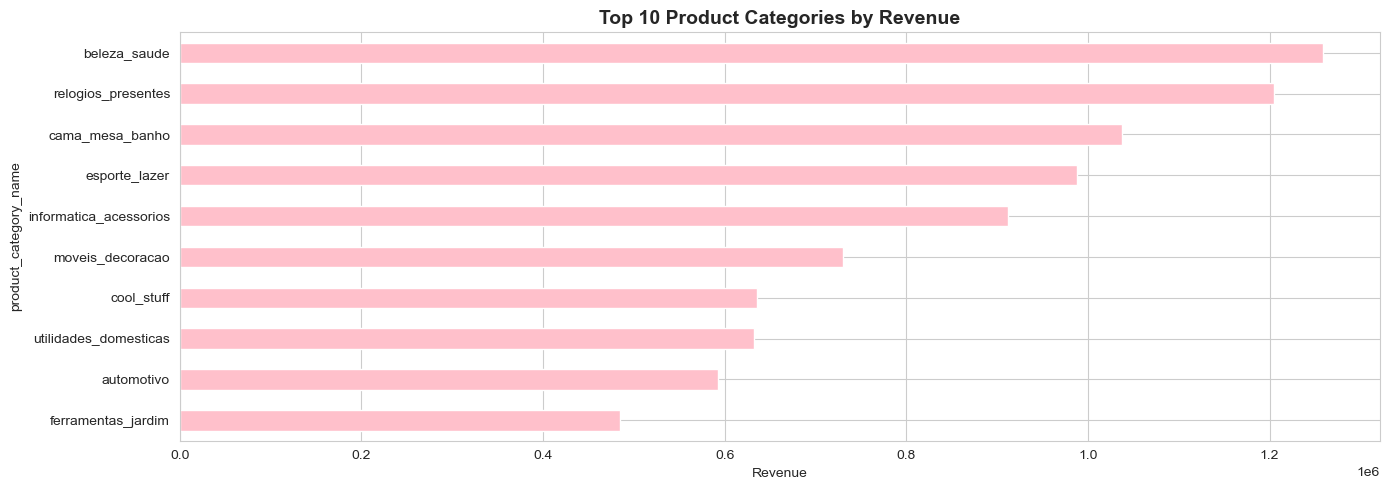

High revenue with moderate orders = high-ticket considered purchases, not impulse buys.


In [14]:
cat_rev = (order_items.merge(products, on='product_id')
           .groupby('product_category_name')['price']
           .sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(14, 5))
cat_rev.plot(kind='barh', color='pink', edgecolor='white')
plt.title('Top 10 Product Categories by Revenue',
          fontsize=14, fontweight='bold')
plt.xlabel('Revenue')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../../05_Analytics/03_Visualizations/03_top_categories.png', dpi=150)
plt.show()
print("High revenue with moderate orders = high-ticket considered purchases, not impulse buys.")

## ⭐ Chart 4: Review Score Distribution
*How satisfied are customers overall?*

Review scores are the customer's voice. The overall distribution tells us sentiment — but the shape of it tells us something deeper.

---

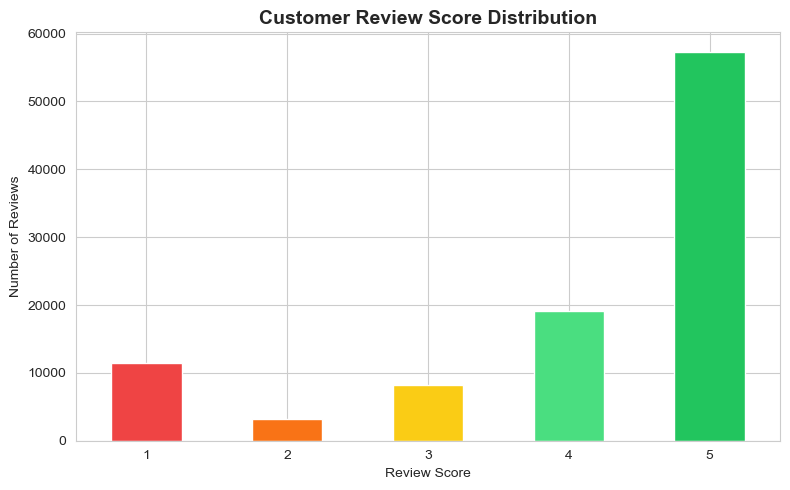

Over 55% gave 5 stars — but 1-star reviews are notable and concentrated in specific categories.


In [21]:
review_counts = reviews['review_score'].value_counts().sort_index()
colors = ['#EF4444','#F97316','#FACC15','#4ADE80','#22C55E']

plt.figure(figsize=(8, 5))
review_counts.plot(kind='bar', color=colors, edgecolor='white')
plt.title('Customer Review Score Distribution',
          fontsize=14, fontweight='bold')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../../05_Analytics/03_Visualizations/04_review_scores.png', dpi=150)
plt.show()
print("Over 55% gave 5 stars — but 1-star reviews are notable and concentrated in specific categories.")

## 🚚 Chart 5: Delivery Delay Distribution
*How often does Olist deliver late — and how bad is it when they do?*

The customer experience doesn't end at checkout. Late deliveries are the top reason for 1-star reviews and lost customers.

---

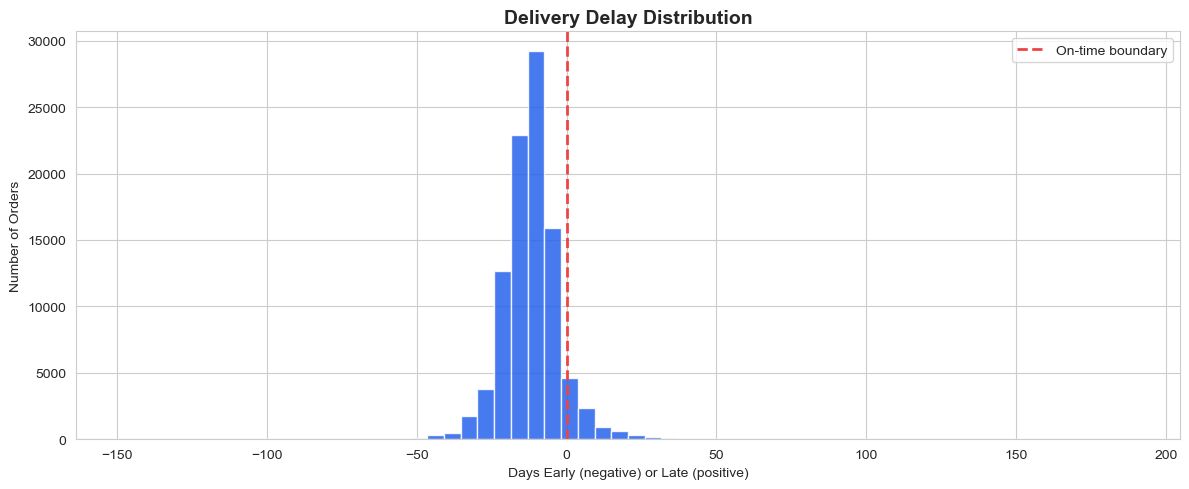

Most orders arrive early — but late deliveries skew very late, hurting satisfaction in specific regions.


In [23]:
delay_data = orders[orders['delivery_delay'].notna()]

plt.figure(figsize=(12, 5))
plt.hist(delay_data['delivery_delay'], bins=60,
         color='#2563EB', edgecolor='white', alpha=0.85)
plt.axvline(0, color='#EF4444', linestyle='--',
            linewidth=2, label='On-time boundary')
plt.title('Delivery Delay Distribution',
          fontsize=14, fontweight='bold')
plt.xlabel('Days Early (negative) or Late (positive)')
plt.ylabel('Number of Orders')
plt.legend()
plt.tight_layout()
plt.savefig('../../05_Analytics/03_Visualizations/05_delivery_delay.png', dpi=150)
plt.show()
print("Most orders arrive early — but late deliveries skew very late, hurting satisfaction in specific regions.")

## 💳 Chart 6: Revenue by Payment Method
*How do customers prefer to pay — and what does that reveal?*

Payment behavior tells us about customer demographics and financial confidence — and where the business might be vulnerable.

---

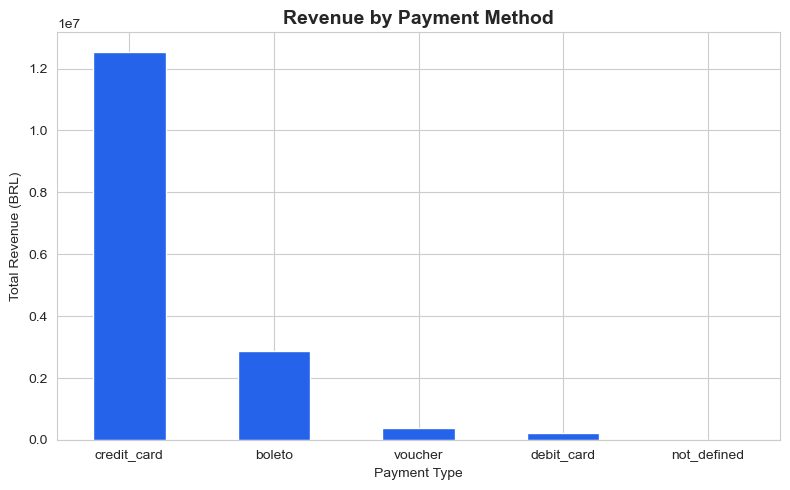

Credit card dominates — but high installment use tells us customers are price-sensitive.


In [25]:
pay_rev = (payments.groupby('payment_type')['payment_value']
           .sum().sort_values(ascending=False))

plt.figure(figsize=(8, 5))
pay_rev.plot(kind='bar', color='#2563EB', edgecolor='white')
plt.title('Revenue by Payment Method',
          fontsize=14, fontweight='bold')
plt.xlabel('Payment Type')
plt.ylabel('Total Revenue (BRL)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../../05_Analytics/03_Visualizations/06_payment_methods.png', dpi=150)
plt.show()
print("Credit card dominates — but high installment use tells us customers are price-sensitive.")

## 💡 EDA Key Takeaways

- Revenue grew steadily 2017–2018 with a clear **Black Friday peak in Nov 2017**
- **São Paulo = ~40% of revenue** — in a league of its own
- Over 55% give 5 stars but **1-star reviews concentrate in specific categories**
- Most deliveries arrive early — but **late ones are significantly late**, not just by a day
- Basket size ~1 item — people buy specific products, not browse
- High installment use confirms customers are **price-sensitive**

---